In [5]:
!pip install selenium

In [6]:
import pandas as pd # use for data manipulation and analysis
import numpy as np # use for multi-dimensional array and matrix

import seaborn as sns # use for high-level interface for drawing attractive and informative statistical graphics
import matplotlib.pyplot as plt # It provides an object-oriented API for embedding plots into applications
%matplotlib inline
# It sets the backend of matplotlib to the 'inline' backend:
import plotly.express as px
import time # calculate time

from sklearn.linear_model import LogisticRegression # algo use to predict good or bad
from sklearn.naive_bayes import MultinomialNB # nlp algo use to predict good or bad

from sklearn.model_selection import train_test_split # spliting the data between feature and target
from sklearn.metrics import classification_report # gives whole report about metrics (e.g, recall,precision,f1_score,c_m)
from sklearn.metrics import confusion_matrix # gives info about actual and predict
from nltk.tokenize import RegexpTokenizer # regexp tokenizers use to split words from text
from nltk.stem.snowball import SnowballStemmer # stemmes words
from sklearn.feature_extraction.text import CountVectorizer # create sparse matrix of words using regexptokenizes
from sklearn.pipeline import make_pipeline # use for combining all prerocessors techniuqes and algos

from PIL import Image # getting images in notebook
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator# creates words colud

from bs4 import BeautifulSoup # use for scraping the data from website
from selenium import webdriver # use for automation chrome
import networkx as nx # for the creation, manipulation, and study of the structure, dynamics, and functions of complex networks.

import pickle# use to dump model

import warnings # ignores pink warnings
warnings.filterwarnings('ignore')

In [7]:
# Loading the dataset
phish_data = pd.read_csv('/content/phishing_site_urls.csv')

In [8]:
phish_data.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [9]:
phish_data.tail()

,URL,Label
60060,www.cse.iitd.ernet.in/~ssen,good
60061,www.isical.ac.in/~uma/,good
60062,www.cse.psu.edu/~anand/,good
60063,www.cse.iitb.ac.in/~siva/,good
60064,mcs.une.edu,NaN


In [10]:
phish_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60065 entries, 0 to 60064
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   URL     60065 non-null  object
 1   Label   60064 non-null  object
dtypes: object(2)
memory usage: 938.6+ KB


About dataset
Data is containg 5,49,346 unique entries.
There are two columns.
Label column is prediction col which has 2 categories A. Good - which means the urls is not containing malicious stuff and this site is not a Phishing Site. B. Bad - which means the urls contains malicious stuffs and this site isa Phishing Site.
There is no missing value in the dataset.

In [11]:
phish_data.isnull().sum() # there is no missing values

,0
URL,0
Label,1


In [12]:
phish_data

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad
...,...,...
60060,www.cse.iitd.ernet.in/~ssen,good
60061,www.isical.ac.in/~uma/,good
60062,www.cse.psu.edu/~anand/,good
60063,www.cse.iitb.ac.in/~siva/,good


In [13]:
from sklearn.impute import SimpleImputer

# Create an imputer object
imputer = SimpleImputer(strategy='most_frequent')

# Fit and transform the imputer on the 'Label' column, and then flatten the result to 1D
phish_data['Label'] = imputer.fit_transform(phish_data[['Label']]).flatten()

In [14]:
phish_data['Label'].fillna('bad', inplace=True)

 **it is classification problems so let's see the classes are balanced or imbalances**

In [15]:
#create a dataframe of classes counts
# Calculate the counts of each unique label
label_counts = phish_data['Label'].value_counts()
# Print the counts
print("Label Counts:\n", label_counts)
# Calculate the proportion of each label
label_proportions = label_counts / len(phish_data)
# Print the proportions
print("\nLabel Proportions:\n", label_proportions)
# Check for imbalance
if label_proportions.min() < 0.4 or label_proportions.max() > 0.6:
  print("\nThe dataset is imbalanced.")
else:
  print("\nThe dataset is balanced.")

Label Counts:
 Label
bad     47905
good    12160
Name: count, dtype: int64

Label Proportions:
 Label
bad     0.797553
good    0.202447
Name: count, dtype: float64

The dataset is imbalanced.


In [16]:
import plotly.express as px

# label_counts = pd.Series({'good': 392924, 'bad': 156422}, name='Label')

# Reset label_counts to a Series from the DataFrame if needed
label_counts = phish_data['Label'].value_counts()  # Get the Series from original data

# Create a DataFrame for px.bar
df_label_counts = label_counts.to_frame().reset_index()  # Convert Series to DataFrame
df_label_counts.columns = ['Label', 'Count'] # Rename columns for clarity

fig = px.bar(
    df_label_counts,  # Pass the DataFrame
    x='Label',  # Specify the column for the x-axis
    y='Count',  # Specify the column for the y-axis
    labels={'x': 'Label', 'y': 'Count'},  # Customize axis labels
    title='Distribution of Labels',  # Add a title
    color='Label',  # Color bars by label category
    color_discrete_sequence=['green', 'red'],  # Choose custom colors
)

fig.show()

**CORRELATED WORDS**

In [17]:
from sklearn.feature_selection import chi2
from sklearn.feature_extraction.text import CountVectorizer

# Drop rows with missing values in the 'URL' column
phish_data.dropna(subset=['URL'], inplace=True)

# Create and fit the CountVectorizer
cv = CountVectorizer()  # Initialize CountVectorizer
feature = cv.fit_transform(phish_data['URL'])  # Fit and transform to create the feature matrix

# Now you can proceed with calculating chi-squared scores
chi2_scores, p_values = chi2(feature, phish_data.Label)

# ... (rest of the code remains the same)

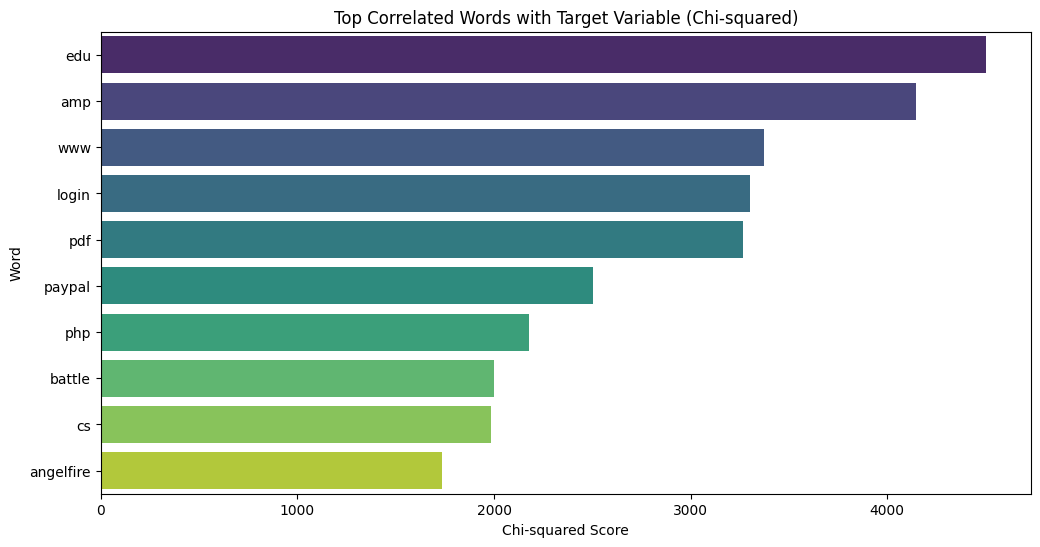

In [18]:
# Create and fit the CountVectorizer
cv = CountVectorizer()  # Initialize CountVectorizer
feature = cv.fit_transform(phish_data['URL'])  # Fit and transform to create the feature matrix

# Calculate chi-squared scores
chi2_scores, p_values = chi2(feature, phish_data.Label)

# Create a DataFrame to store chi-squared scores and features
df_chi2 = pd.DataFrame({'feature': cv.get_feature_names_out(), 'chi2_score': chi2_scores})

# Sort the DataFrame by chi-squared scores in descending order
df_chi2 = df_chi2.sort_values(by='chi2_score', ascending=False)


# Select the top N correlated words for plotting (e.g., top 10)
top_words = df_chi2.head(10)

# Create a bar plot using Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x='chi2_score', y='feature', data=top_words, palette='viridis')  # Use a color palette
plt.title('Top Correlated Words with Target Variable (Chi-squared)')
plt.xlabel('Chi-squared Score')
plt.ylabel('Word')
plt.show()

**Preprocessing**

Now that we have the data, we have to vectorize our URLs. I used CountVectorizer and gather words using tokenizer, since there are words in urls that are more important than other words e.g ‘virus’, ‘.exe’ ,’.dat’ etc. Lets convert the URLs into a vector form.

RegexpTokenizer¶
A tokenizer that splits a string using a regular expression, which matches either the tokens or the separators between tokens.

In [19]:
tokenizer = RegexpTokenizer(r'[A-Za-z]+')#to getting alpha only

In [20]:
phish_data.URL[0]

'nobell.it/70ffb52d079109dca5664cce6f317373782/login.SkyPe.com/en/cgi-bin/verification/login/70ffb52d079109dca5664cce6f317373/index.php?cmd=_profile-ach&outdated_page_tmpl=p/gen/failed-to-load&nav=0.5.1&login_access=1322408526'

In [21]:
# this will be pull letter which matches to expression
tokenizer.tokenize(phish_data.URL[0]) # using first row

['nobell',
 'it',
 'ffb',
 'd',
 'dca',
 'cce',
 'f',
 'login',
 'SkyPe',
 'com',
 'en',
 'cgi',
 'bin',
 'verification',
 'login',
 'ffb',
 'd',
 'dca',
 'cce',
 'f',
 'index',
 'php',
 'cmd',
 'profile',
 'ach',
 'outdated',
 'page',
 'tmpl',
 'p',
 'gen',
 'failed',
 'to',
 'load',
 'nav',
 'login',
 'access']

In [22]:
print('Getting words tokenized ...')
t0= time.perf_counter()
phish_data['text_tokenized'] = phish_data.URL.map(lambda t: tokenizer.tokenize(t)) # doing with all rows
t1 = time.perf_counter() - t0
print('Time taken',t1 ,'sec')

Getting words tokenized ...
Time taken 0.3267760310000085 sec


In [23]:
phish_data.sample(100)

,URL,Label,text_tokenized
45059,www968.paypal.ca.99152.securessl-140.mx/js/web...,bad,"[www, paypal, ca, securessl, mx, js, web, apps..."
39358,paypal-accountcheck.info/80815/index.php,bad,"[paypal, accountcheck, info, index, php]"
50060,www.rapfilms.com/home.html,good,"[www, rapfilms, com, home, html]"
11986,www.picasasicilia.com//components/com_realtyna...,bad,"[www, picasasicilia, com, components, com, rea..."
39860,remax.us.ms/,bad,"[remax, us, ms]"
...,...,...,...
5371,www.dvo-korfbal.nl/modules/fckeditor/fckeditor...,bad,"[www, dvo, korfbal, nl, modules, fckeditor, fc..."
26573,paypal.com.nbrcrestoration.com/cy/cgi-bin/webs...,bad,"[paypal, com, nbrcrestoration, com, cy, cgi, b..."
55936,www.ftc.gov/os/statutes/textile/rr-textl.htm,good,"[www, ftc, gov, os, statutes, textile, rr, tex..."
6922,renacimientocf.org/wp-content/upgrade/cancel/c...,bad,"[renacimientocf, org, wp, content, upgrade, ca..."


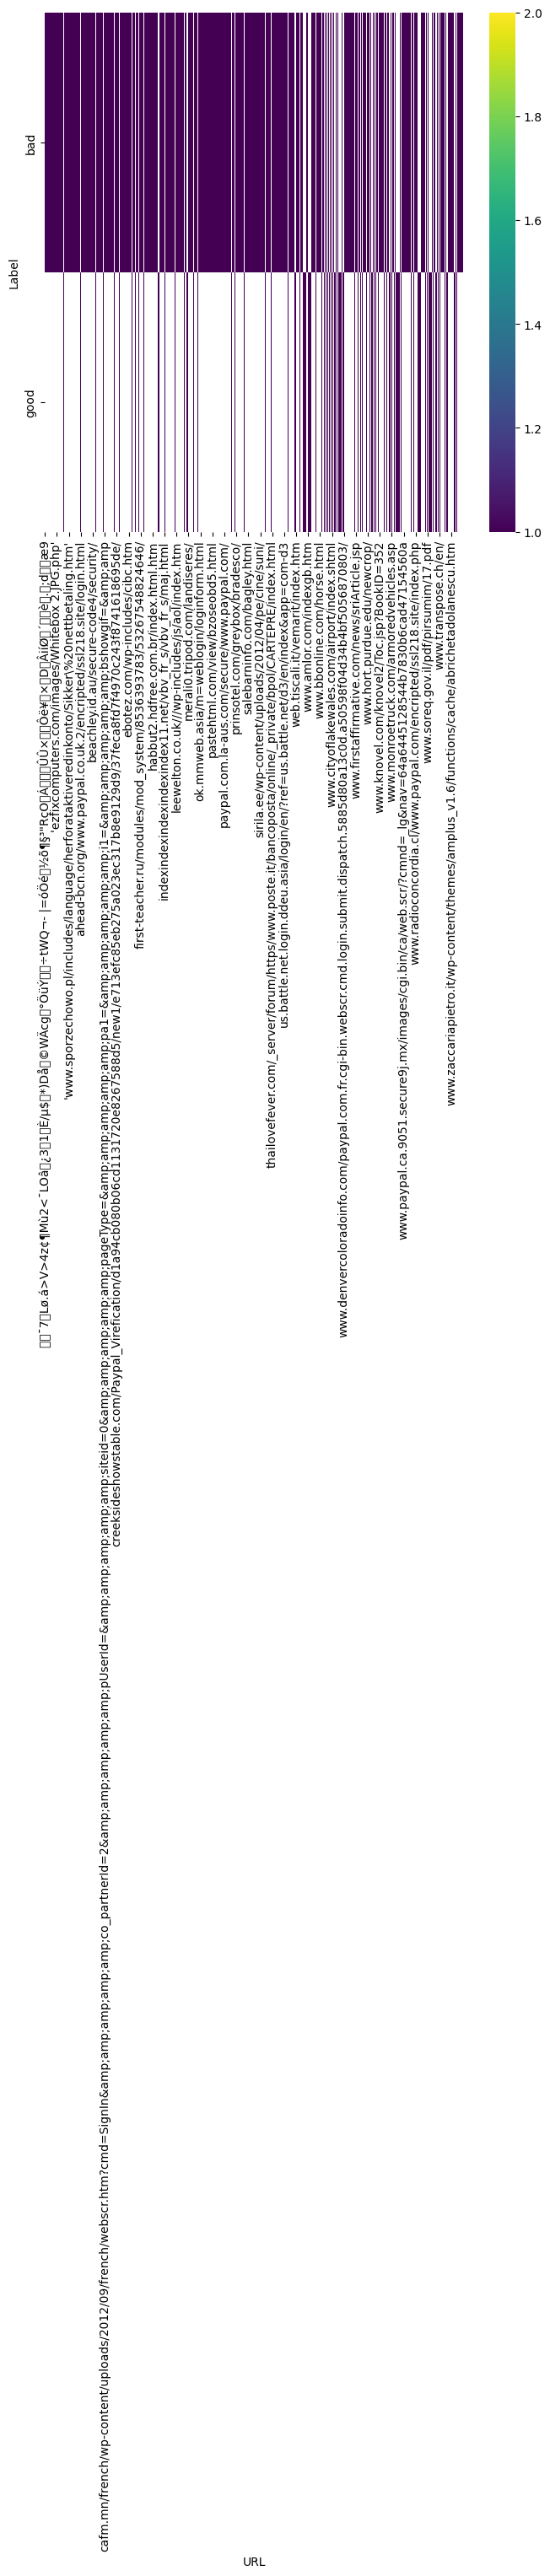

In [24]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
plt.subplots(figsize=(8, 8))
df_2dhist = pd.DataFrame({
    x_label: grp['Label'].value_counts()
    for x_label, grp in phish_data.groupby('URL')
})
sns.heatmap(df_2dhist, cmap='viridis')
plt.xlabel('URL')
_ = plt.ylabel('Label')

**string processing language**

SnowballStemmer
Snowball is a small string processing language, gives root words

In [25]:
stemmer = SnowballStemmer("english") # choose a language

In [26]:
print('Getting words stemmed ...')
t0= time.perf_counter()
phish_data['text_stemmed'] = phish_data['text_tokenized'].map(lambda l: [stemmer.stem(word) for word in l])
t1= time.perf_counter() - t0
print('Time taken',t1 ,'sec')

Getting words stemmed ...
Time taken 4.612920945000042 sec


In [27]:
phish_data.sample(5)

,URL,Label,text_tokenized,text_stemmed
44150,estudioparaiso.org/638c4775c695a661c817cd6ea69...,bad,"[estudioparaiso, org, c, c, a, c, cd, ea, bb, dk]","[estudioparaiso, org, c, c, a, c, cd, ea, bb, dk]"
41852,'9d345009-a-62cb3a1a-s-sites.googlegroups.com/...,bad,"[d, a, cb, a, a, s, sites, googlegroups, com, ...","[d, a, cb, a, a, s, site, googlegroup, com, si..."
54859,cxocommunication.com/home.html,good,"[cxocommunication, com, home, html]","[cxocommun, com, home, html]"
30845,'www.slbbanknepal.com/site\%202013/scam\%20pay...,bad,"[www, slbbanknepal, com, site, scam, paypal, s...","[www, slbbanknep, com, site, scam, paypal, sca..."
24342,'webpremiosevoce.com/comprapremiada/xsl/?\%C2\...,bad,"[webpremiosevoce, com, comprapremiada, xsl, C,...","[webpremiosevoc, com, comprapremiada, xsl, c, ..."


In [28]:
print('Getting joiningwords ...')
t0= time.perf_counter()
phish_data['text_sent'] = phish_data['text_stemmed'].map(lambda l: ' '.join(l))
t1= time.perf_counter() - t0
print('Time taken',t1 ,'sec')

Getting joiningwords ...
Time taken 0.04034125400016819 sec


In [29]:
phish_data.sample(5)

,URL,Label,text_tokenized,text_stemmed,text_sent
5017,jundajx.com/images/?us.battle.net/login/en/?re...,bad,"[jundajx, com, images, us, battle, net, login,...","[jundajx, com, imag, us, battl, net, login, en...",jundajx com imag us battl net login en ref us ...
50743,alissaallen.com/lifestyle/,good,"[alissaallen, com, lifestyle]","[alissaallen, com, lifestyl]",alissaallen com lifestyl
5234,islander.it/images/cani/frida/gdf5gdf4gd5g4d6f...,bad,"[islander, it, images, cani, frida, gdf, gdf, ...","[island, it, imag, cani, frida, gdf, gdf, gd, ...",island it imag cani frida gdf gdf gd g d f g d...
5844,cafm.mn/french/wp-content/uploads/2012/09/fren...,bad,"[cafm, mn, french, wp, content, uploads, frenc...","[cafm, mn, french, wp, content, upload, french...",cafm mn french wp content upload french webscr...
51232,www.cruzcebola.com/pedras.htm,good,"[www, cruzcebola, com, pedras, htm]","[www, cruzcebola, com, pedra, htm]",www cruzcebola com pedra htm


**Visualization**


 Visualize some important keys using word cloud

In [30]:
#sliceing classes
bad_sites = phish_data[phish_data.Label == 'bad']
good_sites = phish_data[phish_data.Label == 'good']

In [31]:
bad_sites.head()

,URL,Label,text_tokenized,text_stemmed,text_sent
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, ffb, d, dca, cce, f, login, SkyPe...","[nobel, it, ffb, d, dca, cce, f, login, skype,...",nobel it ffb d dca cce f login skype com en cg...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [32]:
good_sites.head()

,URL,Label,text_tokenized,text_stemmed,text_sent
18231,esxcc.com/js/index.htm?us.battle.net/noghn/en/...,good,"[esxcc, com, js, index, htm, us, battle, net, ...","[esxcc, com, js, index, htm, us, battl, net, n...",esxcc com js index htm us battl net noghn en r...
18232,wwweira¯&nvinip¿ncH¯wVö%ÆåyDaHðû/ÏyEùuË\nÓ6...,good,"[www, eira, nvinip, ncH, wV, yDaH, yE, u, rT, ...","[www, eira, nvinip, nch, wv, ydah, ye, u, rt, ...",www eira nvinip nch wv ydah ye u rt u g m i xz...
18233,'www.institutocgr.coo/web/media/syqvem/dk-óij...,good,"[www, institutocgr, coo, web, media, syqvem, d...","[www, institutocgr, coo, web, media, syqvem, d...",www institutocgr coo web media syqvem dk ij r ...
18234,Yìê koãÕ»Î§DéÎl½ñ¡ââqtò¸/à; Í,good,"[Y, ko, D, l, qt]","[y, ko, d, l, qt]",y ko d l qt
18236,ruta89fm.com/images/AS@Vies/1i75cf7b16vc<Fd16...,good,"[ruta, fm, com, images, AS, Vies, i, cf, b, vc...","[ruta, fm, com, imag, as, vie, i, cf, b, vc, f...",ruta fm com imag as vie i cf b vc f d b g sd v...


**create a function to visualize the important keys from url**

In [33]:
def plot_wordcloud(text, mask=None, max_words=400, max_font_size=120, figure_size=(24.0,16.0),
                   title = None, title_size=40, image_color=False):
    stopwords = set(STOPWORDS)
    more_stopwords = {'com','http'}
    stopwords = stopwords.union(more_stopwords)

    wordcloud = WordCloud(background_color='white',
                    stopwords = stopwords,
                    max_words = max_words,
                    max_font_size = max_font_size,
                    random_state = 42,
                    mask = mask)
    wordcloud.generate(text)

    plt.figure(figsize=figure_size)
    if image_color:
        image_colors = ImageColorGenerator(mask);
        plt.imshow(wordcloud.recolor(color_func=image_colors), interpolation="bilinear");
        plt.title(title, fontdict={'size': title_size,
                                  'verticalalignment': 'bottom'})
    else:
        plt.imshow(wordcloud);
        plt.title(title, fontdict={'size': title_size, 'color': 'green',
                                  'verticalalignment': 'bottom'})
    plt.axis('off');
    plt.tight_layout()
d = '../input/masks/masks-wordclouds/'

In [34]:
data = good_sites.text_sent
data.reset_index(drop=True, inplace=True)

code for good sites
"common_text = str(data)
common_mask = np.array(Image.open(d+'comment.png'))
plot_wordcloud(common_text, common_mask, max_words=400, max_font_size=120,
               title = 'Most common words use in bad urls', title_size=15)"

**Creating Model¶**
*CountVectorizer*
CountVectorizer is used to transform a corpora of text to a vector of term / token counts.

In [35]:
#create cv object
cv = CountVectorizer()

In [36]:
help(CountVectorizer())

Help on CountVectorizer in module sklearn.feature_extraction.text object:

class CountVectorizer(_VectorizerMixin, sklearn.base.BaseEstimator)
 |  CountVectorizer(
 |      *,
 |      input='content',
 |      encoding='utf-8',
 |      decode_error='strict',
 |      strip_accents=None,
 |      lowercase=True,
 |      preprocessor=None,
 |      tokenizer=None,
 |      stop_words=None,
 |      token_pattern='(?u)\\b\\w\\w+\\b',
 |      ngram_range=(1, 1),
 |      analyzer='word',
 |      max_df=1.0,
 |      min_df=1,
 |      max_features=None,
 |      vocabulary=None,
 |      binary=False,
 |      dtype=<class 'numpy.int64'>
 |  )
 |
 |  Convert a collection of text documents to a matrix of token counts.
 |
 |  This implementation produces a sparse representation of the counts using
 |  scipy.sparse.csr_matrix.
 |
 |  If you do not provide an a-priori dictionary and you do not use an analyzer
 |  that does some kind of feature selection then the number of features will
 |  be equal to the 

In [37]:
feature = cv.fit_transform(phish_data.text_sent) #transform all text which we tokenize and stemed

In [38]:
feature[:5].toarray() # convert sparse matrix into array to print transformed features

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

**handling data imbalance**, by using random undersampling technique

In [39]:
!pip install imblearn

In [40]:
from imblearn.under_sampling import RandomUnderSampler

# Separate features and target variable
X = phish_data['text_sent']  # Assuming 'text_sent' is your feature column
y = phish_data['Label']

# Create a RandomUnderSampler object
rus = RandomUnderSampler(random_state=42)  # Set random_state for reproducibility

# Resample the data
X_resampled, y_resampled = rus.fit_resample(pd.DataFrame(X), y)

# Convert X_resampled back to a Series
X_resampled = X_resampled['text_sent']

# Create a new balanced DataFrame
balanced_phish_data = pd.DataFrame({'text_sent': X_resampled, 'Label': y_resampled})

# Now you can use balanced_phish_data for further processing and model training

In [41]:
# Before Undersampling
label_counts_before = phish_data['Label'].value_counts()
df_label_counts_before = label_counts_before.to_frame().reset_index()
df_label_counts_before.columns = ['Label', 'Count']

fig_before = px.bar(
    df_label_counts_before,
    x='Label',
    y='Count',
    labels={'x': 'Label', 'y': 'Count'},
    title='Distribution of Labels Before Undersampling',
    color='Label',
    color_discrete_sequence=['green', 'red'],
)
fig_before.show()


In [42]:
# After Undersampling
label_counts_after = balanced_phish_data['Label'].value_counts()
df_label_counts_after = label_counts_after.to_frame().reset_index()
df_label_counts_after.columns = ['Label', 'Count']

fig_after = px.bar(
    df_label_counts_after,
    x='Label',
    y='Count',
    labels={'x': 'Label', 'y': 'Count'},
    title='Distribution of Labels After Undersampling',
    color='Label',
    color_discrete_sequence=['green', 'red'],
)
fig_after.show()

**SPLITTING INTO TRAIN AND TEST**

In [43]:
X = balanced_phish_data['text_sent']
y = balanced_phish_data['Label']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the shapes of the resulting sets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (19456,)
X_test shape: (4864,)
y_train shape: (19456,)
y_test shape: (4864,)


**LogisticRegression¶**
Logistic Regression is a Machine Learning classification algorithm that is used to predict the probability of a categorical dependent variable. In logistic regression, the dependent variable is a binary variable that contains data coded as 1 (yes, success, etc.) or 0 (no, failure, etc.). In other words, the logistic regression model predicts P(Y=1) as a function of X.

In [44]:
# create lr object
lr = LogisticRegression()

In [45]:
trainX, testX, trainY, testY = train_test_split(feature, phish_data.Label)

In [46]:
# create lr object
lr = LogisticRegression()

In [47]:
lr.fit(trainX,trainY)

LogisticRegression()

In [48]:
lr.score(testX,testY)

0.9681694080042619

* Logistic Regression is giving 96% **bold text**accuracy, Now we will store scores in dict to see which model perform best

In [49]:
Scores_ml = {}
Scores_ml['Logistic Regression'] = np.round(lr.score(testX,testY),2)

Training Accuracy : 0.9863256970342745
Testing Accuracy : 0.9681694080042619

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         Bad       0.98      0.98      0.98     12010
        Good       0.92      0.92      0.92      3007

    accuracy                           0.97     15017
   macro avg       0.95      0.95      0.95     15017
weighted avg       0.97      0.97      0.97     15017


CONFUSION MATRIX


<Axes: >

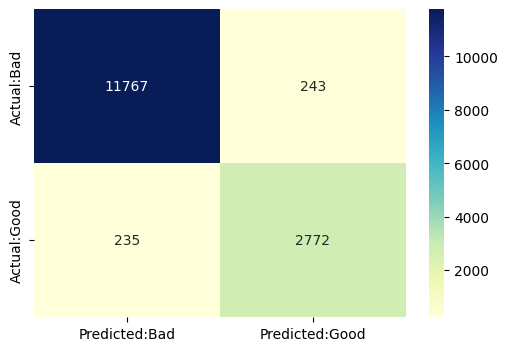

In [50]:
print('Training Accuracy :',lr.score(trainX,trainY))
print('Testing Accuracy :',lr.score(testX,testY))
con_mat = pd.DataFrame(confusion_matrix(lr.predict(testX), testY),
            columns = ['Predicted:Bad', 'Predicted:Good'],
            index = ['Actual:Bad', 'Actual:Good'])


print('\nCLASSIFICATION REPORT\n')
print(classification_report(lr.predict(testX), testY,
                            target_names =['Bad','Good']))

print('\nCONFUSION MATRIX')
plt.figure(figsize= (6,4))
sns.heatmap(con_mat, annot = True,fmt='d',cmap="YlGnBu")

**MultinomialNB¶**
Applying Multinomial Naive Bayes to NLP Problems. Naive Bayes Classifier Algorithm is a family of probabilistic algorithms based on applying Bayes' theorem with the “naive” assumption of conditional independence between every pair of a feature.

In [51]:
# create mnb object
mnb = MultinomialNB()

In [53]:
mnb.fit(trainX,trainY)

MultinomialNB()

In [54]:
mnb.score(testX,testY)

0.9525204767929679

* MultinomialNB **bold text** gives us 95% accuracy

In [55]:
Scores_ml['MultinomialNB'] = np.round(mnb.score(testX,testY),2)

Training Accuracy : 0.9792221630261055
Testing Accuracy : 0.9525204767929679

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         Bad       0.97      0.97      0.97     12081
        Good       0.87      0.89      0.88      2936

    accuracy                           0.95     15017
   macro avg       0.92      0.93      0.93     15017
weighted avg       0.95      0.95      0.95     15017


CONFUSION MATRIX


<Axes: >

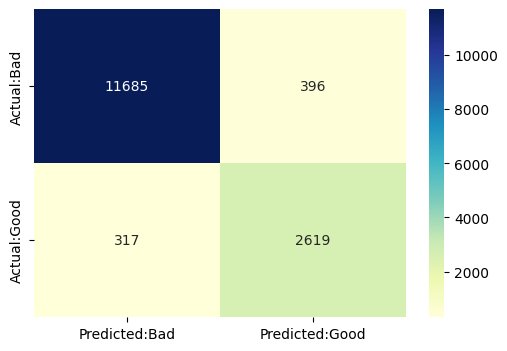

In [56]:
print('Training Accuracy :',mnb.score(trainX,trainY))
print('Testing Accuracy :',mnb.score(testX,testY))
con_mat = pd.DataFrame(confusion_matrix(mnb.predict(testX), testY),
            columns = ['Predicted:Bad', 'Predicted:Good'],
            index = ['Actual:Bad', 'Actual:Good'])


print('\nCLASSIFICATION REPORT\n')
print(classification_report(mnb.predict(testX), testY,
                            target_names =['Bad','Good']))

print('\nCONFUSION MATRIX')
plt.figure(figsize= (6,4))
sns.heatmap(con_mat, annot = True,fmt='d',cmap="YlGnBu")

let see the two models

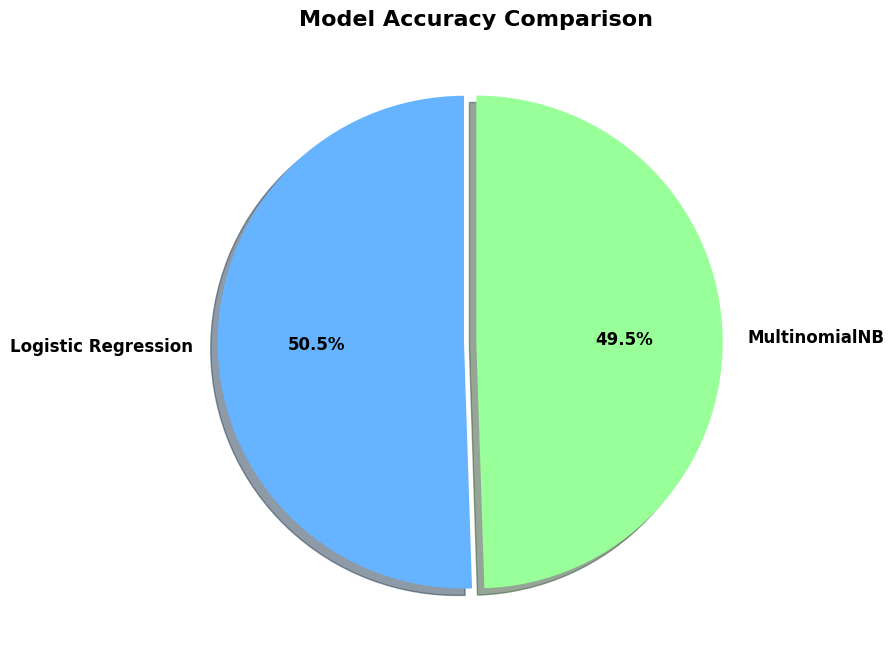

In [57]:
# Define colors for the slices
colors = ['#66b3ff', '#99ff99', '#ff9999', '#ffcc99']  # Example colors (light blue, light green, light red, light orange)


# Function to create a beautiful pie chart
def create_beautiful_pie_chart(scores, title='Model Accuracy Comparison'):
    """Creates a visually appealing pie chart with custom colors, shadows, and exploded slices.

    Args:
        scores (dict): A dictionary containing model names as keys and accuracy scores as values.
        title (str, optional): The title of the pie chart. Defaults to 'Model Accuracy Comparison'.
    """

    # Get the model names and accuracy scores
    labels = list(scores.keys())
    values = list(scores.values())

    # Create a pie chart with enhancements
    plt.figure(figsize=(8, 8))
    plt.pie(
        values,
        labels=labels,
        autopct='%1.1f%%',
        startangle=90,
        colors=colors[:len(labels)],  # Use colors based on the number of models
        shadow=True,  # Add shadow for depth
        explode=[0.05] + [0] * (len(labels) - 1),  # Explode the first slice
        textprops={'fontsize': 12, 'weight': 'bold'},  # Adjust label font
    )
    plt.title(title, fontsize=16, fontweight='bold')
    plt.show()


# Call the function to create the pie chart
create_beautiful_pie_chart(Scores_ml)

**Building Pipeline**

 Logistic Regression is the best fit model, sklearn pipeline using Logistic Regression

In [58]:
pipeline_ls = make_pipeline(CountVectorizer(tokenizer = RegexpTokenizer(r'[A-Za-z]+').tokenize,stop_words='english'), LogisticRegression())
##(r'\b(?:http|ftp)s?://\S*\w|\w+|[^\w\s]+') ([a-zA-Z]+)([0-9]+)  -- these tolenizers giving me low accuray

In [59]:
trainX, testX, trainY, testY = train_test_split(phish_data.URL, phish_data.Label)

In [60]:
pipeline_ls.fit(trainX,trainY)

Pipeline(steps=[('countvectorizer',
                 CountVectorizer(stop_words='english',
                                 tokenizer=<bound method RegexpTokenizer.tokenize of RegexpTokenizer(pattern='[A-Za-z]+', gaps=False, discard_empty=True, flags=re.UNICODE|re.MULTILINE|re.DOTALL)>)),
                ('logisticregression', LogisticRegression())])

In [61]:
pipeline_ls.score(testX,testY)

0.9688353199706998

Training Accuracy : 0.9867696679097852
Testing Accuracy : 0.9688353199706998

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         Bad       0.98      0.98      0.98     12011
        Good       0.92      0.93      0.92      3006

    accuracy                           0.97     15017
   macro avg       0.95      0.95      0.95     15017
weighted avg       0.97      0.97      0.97     15017


CONFUSION MATRIX


<Axes: >

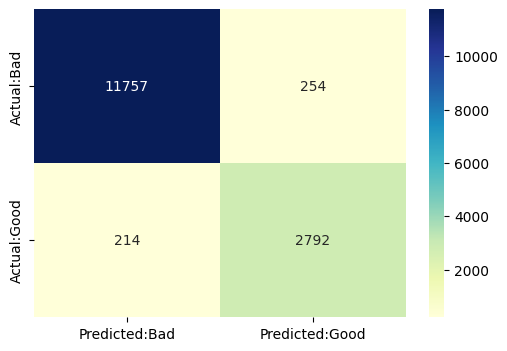

In [62]:
print('Training Accuracy :',pipeline_ls.score(trainX,trainY))
print('Testing Accuracy :',pipeline_ls.score(testX,testY))
con_mat = pd.DataFrame(confusion_matrix(pipeline_ls.predict(testX), testY),
            columns = ['Predicted:Bad', 'Predicted:Good'],
            index = ['Actual:Bad', 'Actual:Good'])


print('\nCLASSIFICATION REPORT\n')
print(classification_report(pipeline_ls.predict(testX), testY,
                            target_names =['Bad','Good']))

print('\nCONFUSION MATRIX')
plt.figure(figsize= (6,4))
sns.heatmap(con_mat, annot = True,fmt='d',cmap="YlGnBu")

In [ ]:
pickle.dump(pipeline_ls,open('phishing.pkl','wb'))

In [ ]:
loaded_model = pickle.load(open('phishing.pkl', 'rb'))
result = loaded_model.score(testX,testY)
print(result)

**MODEL TESTING**

We get an accuracy of 96%. That’s a very high value for a machine to be able to detect a malicious URL with. Want to test some links to see if the model gives good predictions? Sure. Let's do it

Bad links => this are phishing sites yeniik.com.tr/wp-admin/js/login.alibaba.com/login.jsp.php fazan-pacir.rs/temp/libraries/ipad www.tubemoviez.exe svision-online.de/mgfi/administrator/components/com_babackup/classes/fx29id1.txt

Good links => this are not phishing sites www.youtube.com/ youtube.com/watch?v=qI0TQJI3vdU https://uniuyo.edu.ng/eportals/ restorevisioncenters.com/html/technology.html

In [ ]:
predict_bad = ['yeniik.com.tr/wp-admin/js/login.alibaba.com/login.jsp.php','fazan-pacir.rs/temp/libraries/ipad','tubemoviez.exe','svision-online.de/mgfi/administrator/components/com_babackup/classes/fx29id1.txt']
predict_good = ['youtube.com/','youtube.com/watch?v=qI0TQJI3vdU','uniuyo.edu.ng/eportals/','restorevisioncenters.com/html/technology.html']
loaded_model = pickle.load(open('phishing.pkl', 'rb'))
#predict_bad = vectorizers.transform(predict_bad)
# predict_good = vectorizer.transform(predict_good)
result = loaded_model.predict(predict_bad)
result2 = loaded_model.predict(predict_good)
print(result)
print("*"*30)
print(result2)

In [ ]:
predict_good = ['uniuyo.edu.ng/eportals/']
loaded_model = pickle.load(open('phishing.pkl', 'rb'))
#predict_bad = vectorizers.transform(predict_bad)
# predict_good = vectorizer.transform(predict_good)
result = loaded_model.predict(predict_good)
print(result)
